# 01 - Exploratory data analysis (24 charts)
Charts come from `src/eda.py` (saved to `images/eda_*.png`); the findings below are computed in code, not typed.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, json
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
from src import eda
F = eda.run(); F

{'disbursed_default_rate_pct': np.float64(23.4), 'approval_rate_decided_pct': np.float64(46.4), 'default_rate_by_loan_type_pct': {'Personal': 20.3, 'Auto': 21.3, 'Gold': 23.3, 'Education': 27.4, 'Business': 29.7, 'Home': 31.6}, 'approval_rate_by_loan_type_pct': {'Home': 26.0, 'Business': 27.9, 'Education': 46.2, 'Auto': 48.7, 'Personal': 55.8, 'Gold': 63.5}, 'default_rate_by_score_band_pct': {'<580': 39.9, '580-649': 34.8, '650-699': 24.4, '700-749': 16.8, '750+': 11.5}, 'default_rate_by_dti_band_pct': {'<0.3': 9.1, '0.3-0.5': 13.9, '0.5-0.8': 17.6, '0.8-1.2': 24.8, '>1.2': 41.7}, 'dti_band_counts': {'<0.3': 363, '0.3-0.5': 700, '0.5-0.8': 829, '0.8-1.2': 645, '>1.2': 866}, 'default_rate_by_employment_pct': {'Salaried': 20.8, 'Business Owner': 23.7, 'Self-Employed': 28.8, 'Retired': 28.8, 'Unemployed': 45.8}, 'employment_counts': {'Salaried': 2041, 'Business Owner': 477, 'Self-Employed': 698, 'Retired': 163, 'Unemployed': 24}, 'applications_per_month_min_max': [265, 357], 'approval_rat

24 charts


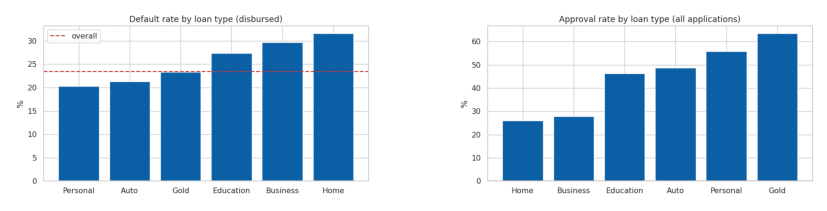

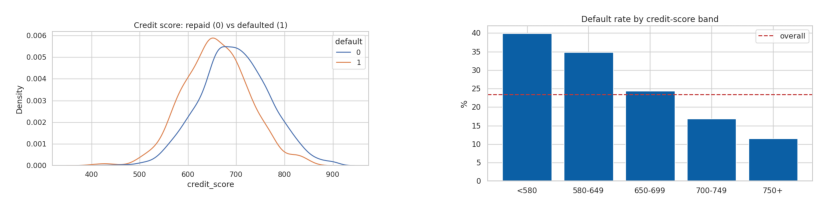

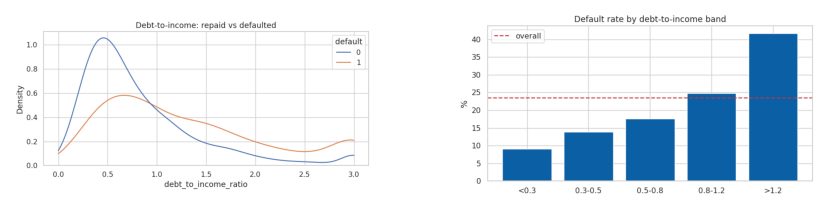

In [2]:
import matplotlib.image as mpimg, glob
files = sorted(glob.glob('../images/eda_*.png')); print(len(files), 'charts')
def show(idx):
    fig, axs = plt.subplots(1, len(idx), figsize=(7.5 * len(idx), 4.4)); axs = np.atleast_1d(axs)
    for a, i in zip(axs, idx): a.imshow(mpimg.imread(files[i])); a.axis('off')
    plt.show()
show([0, 1]); show([2, 3]); show([4, 5])

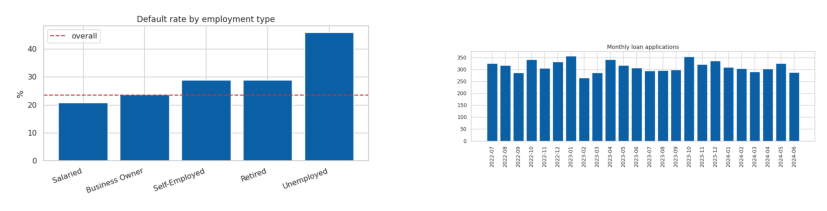

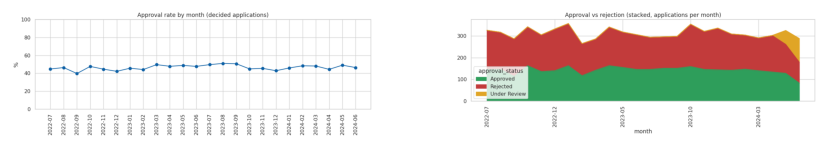

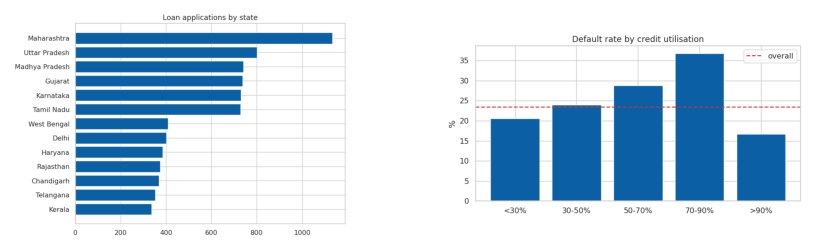

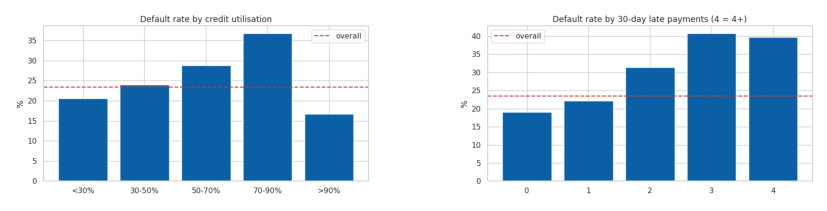

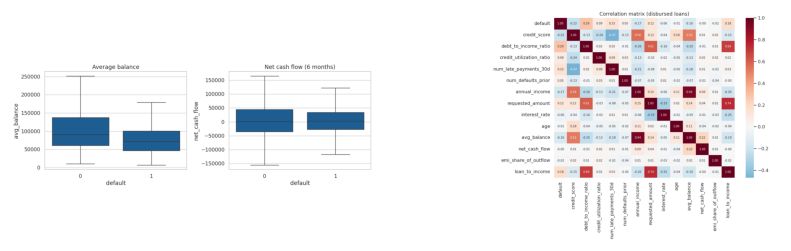

In [3]:
show([6, 8]); show([9, 10]); show([12, 14]); show([14, 15]); show([16, 17])

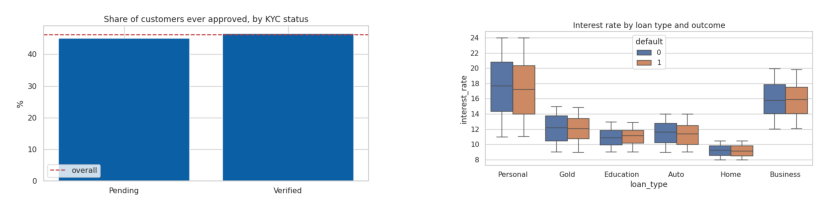

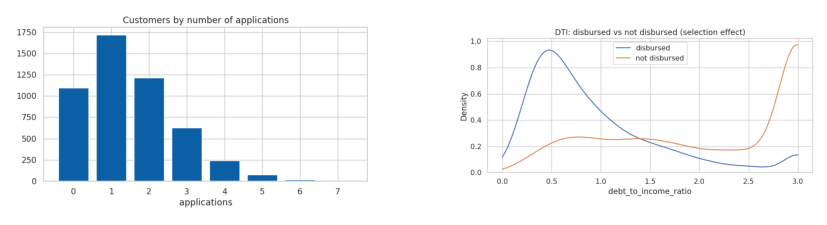

In [4]:
show([18, 21]); show([22, 23])

## What the EDA says - and what it warns about
* **Strongest single signal is debt-to-income**: default rate climbs steeply across DTI bands (see `default_rate_by_dti_band_pct`), correlation 0.29 with default. Credit score is second (-0.22).
* **Credit utilisation is NOT monotonic**: the >90% bucket has a *lower* default rate than 70-90% (computed above). Likely few, unusual customers - a reminder not to assume textbook relationships.
* **Selection effect (chart 24)**: disbursed loans have median DTI 0.71, non-disbursed 2.39. We only observe repayment for loans the business already judged safe, so any model trained on them *cannot be validated* on the applications it rejected.
* **Geography and time**: approval rate varies only ~8 points across states and ~11 points across months; default rate by state ranges ~10 points on small samples - mostly noise.
* **Unemployed** applicants default at ~46% but only 24 disbursed loans - too few to rely on.
* 22% of customers (1,096) never applied; 56% of disbursed rows belong to a customer with more than one loan (why splits must be by customer).

In [5]:
# does the DTI effect survive a significance check? two-proportion z-test, DTI > 0.5 vs <= 0.5 on disbursed loans
a = pd.read_csv('../data/processed/application_features.csv'); d = a[a.loan_default.notna()]
x, y = d[d.debt_to_income_ratio > .5].loan_default, d[d.debt_to_income_ratio <= .5].loan_default
p = (x.sum() + y.sum()) / (len(x) + len(y)); z = (x.mean() - y.mean()) / np.sqrt(p * (1 - p) * (1 / len(x) + 1 / len(y)))
print(f'DTI>0.5: n={len(x)} default {x.mean():.3f} | DTI<=0.5: n={len(y)} default {y.mean():.3f} | z={z:.1f}')

DTI>0.5: n=2340 default 0.285 | DTI<=0.5: n=1063 default 0.122 | z=10.4
